# v4.1.5 - Manual clustering: v3 + a 750 km radius

Same method as **v3.1.5** (fit on `complete` + `partial`, direction-balanced
sample with alpha = 0, K sweep with 3 seeds, pathways >= 400 km apart that
reappear in every run, NBC-box exit sides, hierarchical view, real tracks),
with one change: the circles are **200, 500, 750, 1000, 1500, 2000 km**.

**Why 750 km.** Between 500 and 1000 km there was no circle, so where a route
turns in that stretch (e.g. the retroflection around 6-8N) only showed up as a
straight segment from the 500 km to the 1000 km point; some clusters did not
cover that gap. A 750 km circle puts a point there.

**Weights.** The same radius² ramp as v3, now over six radii (mean 1):
`{200: 0.030, 500: 0.185, 750: 0.417, 1000: 0.741, 1500: 1.667, 2000: 2.964}`.
Adding a radius also adds its weight, so the 1000-2000 km points count a
little less than in v3 relative to the whole.

**Data.** The 750 km exit points are in `data/features_r750.parquet`
(extracted by `data/extract_r750.py`, same row order as `features.parquet`,
same rule: a particle that never gets 750 km away keeps its last position).
`features.parquet` itself is unchanged, so v3 still works as before.

**Comparison with v3.** The K sweep below is run for v4; v3's saved sweep
(5 radii, same samples and seeds) is drawn next to it. Pathway distances now
average over six points instead of five, so counts are close but not exactly
like-for-like. (In the radius experiments on 3 M particles, a set with 50-2000
km including 750 km had slightly fewer separated pathways than the 5 radii -
18.5 vs 19.2 - but that test did not target the 500-1000 km gap.)

The 1.5 cross-check of v3 (K = 20 fit) is not repeated here.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # project root: config.py, pipeline.py
import numpy as np
import pandas as pd
import config as C
import pipeline as P
print("project root:", C.PROJECT_ROOT)
print(f"crossing: {C.LAT_CROSS} N | radii (km): {C.RADII_KM}")

import time
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

project root: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius
crossing: 2.5 N | radii (km): [200, 500, 1000, 1500, 2000]


In [2]:
K_SWEEP = [50, 100, 150, 200, 250, 300, 400, 500]   # K values to try
RADII_V4 = [200, 500, 750, 1000, 1500, 2000]          # v3 radii + 750 km
# radius weights ~ radius^2 (as v3), over the six radii, mean 1
RADIUS_WEIGHTS = {200: 0.030, 500: 0.185, 750: 0.417, 1000: 0.741, 1500: 1.667, 2000: 2.964}
RUN_COMPARISON = True            # draw v3's saved sweep (5 radii) next to v4's
RUN_SWEEP = False                # False: load the saved v4 sweep (data/experiments/v4_k_sweep.csv) once it exists; True: recompute (~12 min)
# box used to classify how pathways leave the NBC region (lon0, lon1, lat0, lat1)
# = (west, east, south, north). The NBC box is 55-45W / 5-10N; its west side is
# moved out to 56.2W and its north side to 11N; east (45W) and south (5N) are the
# original NBC box.
NBC_BOX = (-56.2, -45.0, 5.0, 11.0)
SEEDS = [42, 1, 7]               # repeated fits (different sample + seed) for reproducibility
BALANCE_ALPHA = 0.0              # 1 as they come, 0 every direction sector equally
PATHWAY_SEP_KM = 400             # two pathways differ if their tracks are >= this far apart (mean over radii)
MATCH_KM = 200                   # a pathway is reproduced if another run has one within this distance
N_SUB = 500_000                  # particles per fit
K = None                         # final K; None -> chosen automatically from the sweep
SAVE_MODEL = False               # True -> write the final fit for notebooks 03 / 04

In [3]:
FIT_STATUS = ["complete", "partial"]
SECTOR_DEG = 15
C.RADII_KM = RADII_V4            # v4: every pipeline helper (feature columns, weights) now uses the six radii
W = P.feature_weight_vector(RADIUS_WEIGHTS)
print("radii:", C.RADII_KM, "| weights:", RADIUS_WEIGHTS,
      "| balance alpha:", BALANCE_ALPHA,
      "| separation:", PATHWAY_SEP_KM, "km")

radii: [200, 500, 750, 1000, 1500, 2000] | weights: {200: 0.03, 500: 0.185, 750: 0.417, 1000: 0.741, 1500: 1.667, 2000: 2.964} | balance alpha: 0.0 | separation: 400 km


## Particles to fit, and their outer direction

In [4]:
features = pd.read_parquet(C.FEATURES_FILE)
_r750 = pd.read_parquet(C.DATA_DIR / "features_r750.parquet")   # 750 km exit points, same row order
assert len(_r750) == len(features), "features_r750.parquet does not match features.parquet - re-run data/extract_r750.py"
for _c in _r750.columns:
    features[_c] = _r750[_c].to_numpy()
del _r750
fitset = features[features.status.isin(FIT_STATUS)].reset_index(drop=True)
del features
R_OUT = C.RADII_KM[-1]
bearing = P.bearing_deg(fitset.cross_lat, fitset.cross_lon,
                        fitset[P.lat_col(R_OUT)], fitset[P.lon_col(R_OUT)])
sector = np.clip(np.floor((bearing + 180) / SECTOR_DEG).astype(int), 0, 360 // SECTOR_DEG - 1)
n_sector = np.bincount(sector, minlength=360 // SECTOR_DEG)
X_all = P.build_feature_matrix(fitset)

tab = pd.DataFrame({"particles": n_sector,
                    "%": (100 * n_sector / n_sector.sum()).round(3)},
                   index=pd.Index([f"{-180 + SECTOR_DEG*i:+4d}..{-180 + SECTOR_DEG*(i+1):+4d}"
                                   for i in range(len(n_sector))], name="direction (deg, 0 N, -90 W)"))
print(f"{len(fitset):,} particles ({', '.join(FIT_STATUS)})")
print(tab[tab.particles > 0].to_string())

def balanced_sample(seed):
    rng = np.random.default_rng(seed)
    w = n_sector[sector].astype(float) ** (BALANCE_ALPHA - 1.0)
    return rng.choice(len(fitset), size=min(N_SUB, len(fitset)), replace=False, p=w / w.sum())

idx0 = balanced_sample(SEEDS[0])
print(f"\nshare with an eastward outer direction: all {100*(bearing > 0).mean():.1f}%, "
      f"in a balanced sample {100*(bearing[idx0] > 0).mean():.1f}%")

15,068,653 particles (complete, partial)
                             particles       %
direction (deg, 0 N, -90 W)                   
-165..-150                           1   0.000
-150..-135                           1   0.000
 -90.. -75                           1   0.000
 -75.. -60                      171888   1.141
 -60.. -45                     9278146  61.572
 -45.. -30                     3960236  26.281
 -30.. -15                     1024693   6.800
 -15..  +0                      276417   1.834
  +0.. +15                      119790   0.795
 +15.. +30                       85780   0.569
 +30.. +45                       68389   0.454
 +45.. +60                       43196   0.287
 +60.. +75                       31748   0.211
 +75.. +90                        7733   0.051
 +90..+105                         581   0.004
+105..+120                          46   0.000
+120..+135                           4   0.000
+135..+150                           2   0.000
+150..+165         


share with an eastward outer direction: all 2.4%, in a balanced sample 40.7%


## Helpers: fit, centroids in degrees, distinct pathways
Centroids in degrees are the mean member position per radius. Track distance =
mean haversine distance between two centroids' exit points over the radii.

In [5]:
def track_dist(A, B):
    nr = A.shape[1] // 2
    D = 0
    for j in range(nr):
        D = D + P.haversine_km(A[:, None, 2*j], A[:, None, 2*j+1], B[None, :, 2*j], B[None, :, 2*j+1])
    return D / nr

def fit_k(k, idx, seed, n_init=10, Wv=None):
    Wv = W if Wv is None else Wv
    X = X_all[idx]
    sc = StandardScaler().fit(X)
    km = MiniBatchKMeans(n_clusters=k, random_state=seed, batch_size=10000,
                         n_init=n_init, max_iter=300).fit(sc.transform(X) * Wv)
    cent = pd.DataFrame(X).groupby(km.labels_).mean().reindex(range(k)).to_numpy()
    return km, sc, cent

def pathways(cent):
    # flat groups of centroids; every pair of groups is >= PATHWAY_SEP_KM apart
    Z = linkage(squareform(track_dist(cent, cent), checks=False), "complete")
    g = fcluster(Z, t=PATHWAY_SEP_KM, criterion="distance") - 1
    return g, np.array([cent[g == i].mean(axis=0) for i in range(g.max() + 1)])

def is_east(tracks, start_lon):
    return P.bearing_deg(C.LAT_CROSS, start_lon, tracks[:, -2], tracks[:, -1]) > 0

BOX = dict(lon0=NBC_BOX[0], lon1=NBC_BOX[1], lat0=NBC_BOX[2], lat1=NBC_BOX[3])   # grouping box
def _inside(lo, la):
    return BOX["lon0"] <= lo <= BOX["lon1"] and BOX["lat0"] <= la <= BOX["lat1"]

def exit_face(lons, lats):
    # side of the NBC box (N, W, E, S) through which a track first leaves it after
    # entering; 'none' = never inside, 'stays' = still inside at its last point
    was_in = False
    for k in range(len(lons) - 1):
        p, q = (lons[k], lats[k]), (lons[k + 1], lats[k + 1])
        if _inside(*p):
            was_in = True
            if not _inside(*q):
                dx, dy, ts = q[0] - p[0], q[1] - p[1], {}
                if dy > 0: ts["N"] = (BOX["lat1"] - p[1]) / dy
                if dy < 0: ts["S"] = (BOX["lat0"] - p[1]) / dy
                if dx < 0: ts["W"] = (BOX["lon0"] - p[0]) / dx
                if dx > 0: ts["E"] = (BOX["lon1"] - p[0]) / dx
                return min(ts, key=ts.get)
        elif not was_in:
            if _inside(*q):
                was_in = True
            else:                                   # segment may cross the whole box
                for t in np.linspace(0, 1, 50)[1:-1]:
                    x, y = p[0] + t * (q[0] - p[0]), p[1] + t * (q[1] - p[1])
                    if _inside(x, y):
                        sub_t = np.linspace(t, 1, 50)
                        return exit_face(list(p[0] + sub_t * (q[0] - p[0])),
                                         list(p[1] + sub_t * (q[1] - p[1])))
    return "stays" if was_in else "none"

def faces(tracks, starts):
    return [exit_face(list(np.r_[starts[i], tracks[i, 1::2]]), list(np.r_[C.LAT_CROSS, tracks[i, 0::2]]))
            for i in range(len(tracks))]

# one colour per exit side of the grouping box, used by every pathway map
FACE_COL = {"N": "tab:blue", "W": "tab:green", "E": "tab:red", "S": "tab:purple", "none": "0.5", "stays": "k"}

## Sweep K: number of distinct pathways and their reproducibility
For every K and seed: fit, group the centroids into pathways, count them (and
the eastward ones), and check whether each pathway reappears in the other runs.

In [6]:
start_all = fitset.cross_lon.to_numpy()

def run_sweep(Wv, label):
    rows, runs = [], {}
    for k in K_SWEEP:
        for seed in SEEDS:
            idx = balanced_sample(seed)
            km_s, sc_s, cent = fit_k(k, idx, seed, Wv=Wv)
            g, ptrack_s = pathways(cent)
            slon = pd.Series(start_all[idx]).groupby(km_s.labels_).mean().reindex(range(k)).to_numpy()
            pstart_s = np.array([slon[g == i].mean() for i in range(g.max() + 1)])
            fc = faces(ptrack_s, pstart_s)
            runs[(k, seed)] = ptrack_s
            rows.append(dict(weights=label, K=k, seed=seed, pathways=len(ptrack_s),
                             east=int(is_east(ptrack_s, pstart_s).sum()),
                             **{f"exit_{f}": fc.count(f) for f in ("N", "W", "E", "S")}))
        for seed in SEEDS:                   # reproducibility of each run's pathways
            others = [runs[(k, s)] for s in SEEDS if s != seed]
            ok = np.all([track_dist(runs[(k, seed)], o).min(axis=1) < MATCH_KM for o in others], axis=0)
            next(r for r in rows if r["K"] == k and r["seed"] == seed)["reproduced_%"] = round(100 * ok.mean())
        print(f"[{label}] K={k:4d}: " + ", ".join(
            f"{r['pathways']} ({r['east']} east, {r['reproduced_%']}%)" for r in rows if r["K"] == k), flush=True)
    return pd.DataFrame(rows)

SWEEP_CACHE = C.DATA_DIR / "experiments" / "v4_k_sweep.csv"
if RUN_SWEEP or not SWEEP_CACHE.exists():
    sweep = run_sweep(W, "v4")
    sweep.to_csv(SWEEP_CACHE, index=False)
else:
    sweep = pd.read_csv(SWEEP_CACHE)
    print("loaded saved sweep:", SWEEP_CACHE, "(set RUN_SWEEP = True to recompute)")
sweep_cmp = None
if RUN_COMPARISON:              # v3 = same method with 5 radii (its saved sweep, weights ~ r²)
    _v3 = pd.read_csv(C.DATA_DIR / "experiments" / "v3_k_sweep.csv")
    sweep_cmp = _v3[_v3.weights == "r2"].assign(weights="v3").reset_index(drop=True)
cols = [c for c in ["pathways", "east", "exit_N", "exit_W", "exit_E", "exit_S", "reproduced_%"] if c in sweep]
pd.concat([sweep, sweep_cmp]).groupby(["weights", "K"])[cols].mean().round(1)

[v4] K=  50: 12 (8 east, 100%), 14 (8 east, 93%), 14 (9 east, 79%)


[v4] K= 100: 15 (9 east, 93%), 16 (10 east, 94%), 18 (12 east, 100%)


[v4] K= 150: 17 (11 east, 94%), 20 (14 east, 80%), 23 (17 east, 83%)


[v4] K= 200: 24 (17 east, 88%), 22 (14 east, 86%), 24 (15 east, 92%)


[v4] K= 250: 27 (18 east, 89%), 25 (18 east, 92%), 25 (18 east, 84%)


[v4] K= 300: 27 (20 east, 93%), 28 (18 east, 93%), 30 (21 east, 83%)


[v4] K= 400: 31 (21 east, 94%), 29 (21 east, 93%), 31 (21 east, 100%)


[v4] K= 500: 33 (24 east, 91%), 34 (23 east, 94%), 33 (23 east, 82%)


pathways  east  exit_N  exit_W  exit_E  exit_S  reproduced_%
weights K                                                                
v3      50       13.0   7.7     NaN     NaN     NaN     NaN          90.3
        100      17.0  10.3     NaN     NaN     NaN     NaN          94.0
        150      19.7  12.3     NaN     NaN     NaN     NaN          95.0
        200      22.3  13.3     NaN     NaN     NaN     NaN          95.3
        250      24.3  16.0     NaN     NaN     NaN     NaN          97.3
        300      27.3  17.7     NaN     NaN     NaN     NaN          89.3
        400      28.0  18.3     NaN     NaN     NaN     NaN          95.0
        500      31.0  19.7     NaN     NaN     NaN     NaN          93.7
v4      50       13.3   8.3     3.0     2.3     6.0     0.0          90.7
        100      16.3  10.3     3.3     2.0     7.3     0.0          95.7
        150      20.0  14.0     4.0     2.3    10.7     0.0          85.7
        200      23.3  15.3     4.7     3.0    11.0     0.0          88.7
        250      25.7  18.0     5.0     2.7    14.0     0.0          88.3
        300      28.3  19.7     5.3     4.0    14.3     0.3          89.7
        400      30.3  21.0     5.3     4.0    16.0     0.3          95.7
        500      33.3  23.3     7.0     4.3    16.0     0.0          89.0

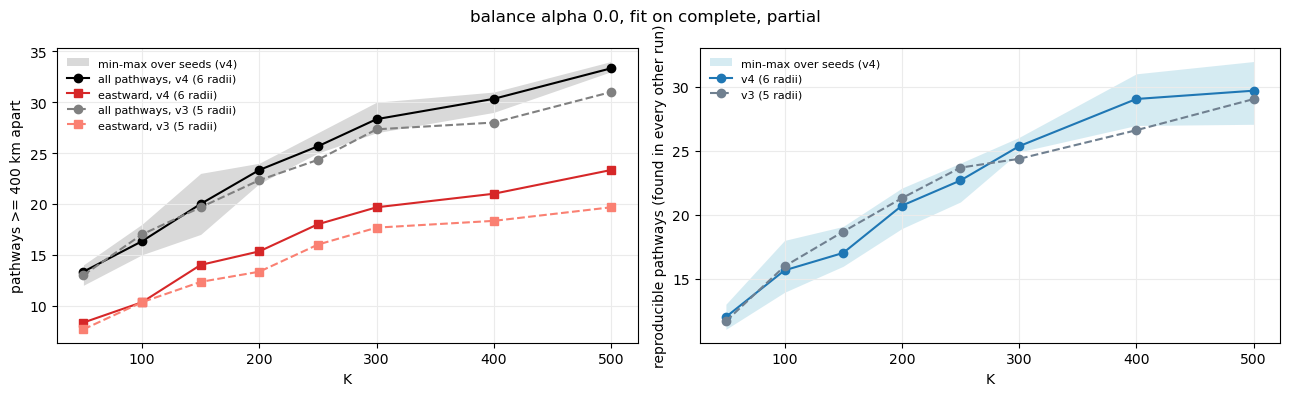

suggested K = 400: 30.3 pathways (21.0 eastward), 96% reproduced = 29.0 reproducible pathways
    v4 (6 radii)                                    v3 (5 radii)                                   
        pathways reproducible % reproduced eastward     pathways reproducible % reproduced eastward
K                                                                                                  
50          13.3         12.0         90.7      8.3         13.0         11.7         90.3      7.7
100         16.3         15.7         95.7     10.3         17.0         16.0         94.0     10.3
150         20.0         17.0         85.7     14.0         19.7         18.7         95.0     12.3
200         23.3         20.7         88.7     15.3         22.3         21.3         95.3     13.3
250         25.7         22.7         88.3     18.0         24.3         23.7         97.3     16.0
300         28.3         25.3         89.7     19.7         27.3         24.4         89.3     17.7
400   

In [7]:
def agg(sw):
    sw = sw.assign(rp=sw.pathways * sw["reproduced_%"] / 100)   # reproducible pathways per run
    return sw.groupby("K").agg(p=("pathways", "mean"), pmin=("pathways", "min"), pmax=("pathways", "max"),
                               e=("east", "mean"), r=("reproduced_%", "mean"),
                               rp=("rp", "mean"), rpmin=("rp", "min"), rpmax=("rp", "max"))
s = agg(sweep)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].fill_between(s.index, s.pmin, s.pmax, color="0.85", lw=0, label="min-max over seeds (v4)")
ax[0].plot(s.index, s.p, "o-", color="k", label="all pathways, v4 (6 radii)")
ax[0].plot(s.index, s.e, "s-", color="tab:red", label="eastward, v4 (6 radii)")
ax[1].fill_between(s.index, s.rpmin, s.rpmax, color="lightblue", alpha=.5, lw=0, label="min-max over seeds (v4)")
ax[1].plot(s.index, s.rp, "o-", color="tab:blue", label="v4 (6 radii)")
if sweep_cmp is not None:
    sc_ = agg(sweep_cmp)
    ax[0].plot(sc_.index, sc_.p, "o--", color="0.5", label="all pathways, v3 (5 radii)")
    ax[0].plot(sc_.index, sc_.e, "s--", color="salmon", label="eastward, v3 (5 radii)")
    ax[1].plot(sc_.index, sc_.rp, "o--", color="slategray", label="v3 (5 radii)")
ax[0].set_xlabel("K"); ax[0].set_ylabel(f"pathways >= {PATHWAY_SEP_KM} km apart")
ax[0].legend(frameon=False, fontsize=8); ax[0].grid(color="0.92")
ax[1].legend(frameon=False, fontsize=8)
ax[1].set_xlabel("K"); ax[1].set_ylabel("reproducible pathways (found in every other run)")
ax[1].grid(color="0.92")
fig.suptitle(f"balance alpha {BALANCE_ALPHA}, fit on {', '.join(FIT_STATUS)}"); fig.tight_layout(); plt.show()

# choice: most pathways among the K whose pathways are >= 95% reproduced (smaller K on ties)
good = s[s.r >= 95]
K_AUTO = int((good if len(good) else s).sort_values(["p", "r"], ascending=[False, False]).index[0])
print(f"suggested K = {K_AUTO}: {s.loc[K_AUTO, 'p']:.1f} pathways "
      f"({s.loc[K_AUTO, 'e']:.1f} eastward), {s.loc[K_AUTO, 'r']:.0f}% reproduced "
      f"= {s.loc[K_AUTO, 'rp']:.1f} reproducible pathways")
_tab = s[["p", "rp", "r", "e"]].rename(columns={"p": "pathways", "rp": "reproducible", "r": "% reproduced", "e": "eastward"})
if sweep_cmp is not None:
    _tab = pd.concat({"v4 (6 radii)": _tab, "v3 (5 radii)": sc_[["p", "rp", "r", "e"]].rename(
        columns={"p": "pathways", "rp": "reproducible", "r": "% reproduced", "e": "eastward"})}, axis=1)
print(_tab.round(1).to_string())
if sweep_cmp is not None:
    ref = sc_.loc[400] if 400 in sc_.index else sc_.iloc[-1]
    match = s[(s.p >= ref.p) & (s.e >= ref.e)]
    print(f"v3 at K={int(ref.name)}: {ref.p:.1f} pathways ({ref.e:.1f} eastward); "
          f"v4 reaches that from K = {int(match.index.min()) if len(match) else 'none of the K tried'}")
if K is None:
    K = K_AUTO
print("K used below:", K)

## Final fit at K
Same balanced sample as the first seed, more initialisations. The pathway of
each cluster (`PATH_OF`) and the share of ALL particles in each pathway (from
labelling a random 2 million) are what the next steps of 1.5 build on.

In [8]:
idx = balanced_sample(SEEDS[0])
sub = fitset.iloc[idx].reset_index(drop=True)
km, scaler, cent_deg = fit_k(K, idx, SEEDS[0], n_init=20)
labels = km.labels_
sizes = np.bincount(labels, minlength=K)
start_lon = sub.groupby(labels).cross_lon.mean().reindex(range(K)).to_numpy()
def centroid_track(c):
    return (np.r_[start_lon[c], cent_deg[c, 1::2]],
            np.r_[C.LAT_CROSS, cent_deg[c, 0::2]])

PATH_OF, ptrack = pathways(cent_deg)
n_path = len(ptrack)
pstart = np.array([start_lon[PATH_OF == i].mean() for i in range(n_path)])
p_east = is_east(ptrack, pstart)
p_face = np.array(faces(ptrack, pstart))

ps = np.random.default_rng(0).choice(len(fitset), size=min(2_000_000, len(fitset)), replace=False)
lab_ps = km.predict(scaler.transform(X_all[ps]) * W)
share = 100 * np.bincount(PATH_OF[lab_ps], minlength=n_path) / len(ps)
cl_count = np.bincount(lab_ps, minlength=K)          # real particles per cluster (in the 2M sample)
ptab = pd.DataFrame({"clusters": np.bincount(PATH_OF, minlength=n_path),
                     "% of all particles": share.round(3), "eastward": p_east,
                     "leaves NBC box via": p_face,
                     f"exit lat {R_OUT}km": ptrack[:, -2].round(1),
                     f"exit lon {R_OUT}km": ptrack[:, -1].round(1)})
ptab.index.name = "pathway"
print(f"fit K={K} on {len(sub):,} particles (balanced) | {n_path} pathways, "
      f"{int(p_east.sum())} eastward | cluster sizes {sizes.min()}..{sizes.max()}")
print("pathways by NBC-box exit side:", pd.Series(p_face).value_counts().to_dict())
ptab.sort_values("% of all particles", ascending=False)

fit K=400 on 500,000 particles (balanced) | 32 pathways, 22 eastward | cluster sizes 157..12968
pathways by NBC-box exit side: {'E': 16, 'W': 6, 'N': 5, 'stays': 5}


,clusters,% of all particles,eastward,leaves NBC box via,exit lat 2000km,exit lon 2000km
pathway,,,,,,
13,41,69.682,False,W,13.2,-64.2
10,31,14.620,False,W,15.9,-59.3
11,19,4.596,False,W,15.4,-56.9
9,25,3.765,False,N,16.5,-55.4
23,15,1.658,False,stays,10.7,-52.4
26,16,1.026,False,N,15.9,-52.7
12,3,0.824,False,W,6.7,-57.4
14,2,0.556,False,stays,5.2,-52.2
24,13,0.509,False,W,13.2,-51.0


In [9]:
# Persist THIS fit for notebooks 03 / 04 (only when SAVE_MODEL is True).
import joblib, json
if SAVE_MODEL:
    MODEL_DIR = C.manual_model_dir(K)
    if MODEL_DIR.exists():
        print("NOTE: overwriting", MODEL_DIR)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(km, MODEL_DIR / f"kmeans_k{K}.pkl")
    joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
    np.save(MODEL_DIR / "weights_W.npy", W)
    np.save(MODEL_DIR / "centroids_deg.npy", cent_deg)
    np.save(MODEL_DIR / "pathway_of_cluster.npy", PATH_OF)
    sub[["trajectory_id", "store", "row", "traj"]].assign(cluster=labels).to_parquet(
        MODEL_DIR / "subsample_labels.parquet", index=False)
    pd.concat([sweep, sweep_cmp]).to_csv(MODEL_DIR / "k_sweep.csv", index=False)
    (MODEL_DIR / "fit_metadata.json").write_text(json.dumps(dict(
        source_notebook="v4.1.5_Manual_clustering.ipynb", K=K, LAT_CROSS=C.LAT_CROSS,
        RADII_KM=C.RADII_KM, RADIUS_WEIGHTS={str(k): v for k, v in RADIUS_WEIGHTS.items()},
        FIT_STATUS=FIT_STATUS, BALANCE_ALPHA=BALANCE_ALPHA, SECTOR_DEG=SECTOR_DEG,
        PATHWAY_SEP_KM=PATHWAY_SEP_KM, n_pathways=int(n_path), N_SUB=N_SUB,
        seed=SEEDS[0], n_fitted=int(len(sub)), cluster_sizes=sizes.tolist()), indent=2))
    print("saved model ->", MODEL_DIR)
else:
    print("SAVE_MODEL is False -> nothing written")

SAVE_MODEL is False -> nothing written


## Cheap coastline

In [10]:
import matplotlib.patches as mpatches

def draw_refs(ax, **kw):
    # reference lines from the day-based notebooks + the 2.5N starting line
    for x in (-70, -60, -40):
        ax.axvline(x, lw=.5, **kw)
    ax.axhline(20, lw=.5, **kw)
    ax.axhline(C.LAT_CROSS, lw=.6, ls="--", color="k")
    ax.add_patch(mpatches.Rectangle(xy=(-55, 5), width=10, height=5, lw=1,
                                    edgecolor="green", facecolor="none"))

_draw_refs_base = draw_refs
def draw_refs(ax, **kw):
    # reference lines + the grouping box (dashed) on top of the NBC box (green)
    _draw_refs_base(ax, **kw)
    ax.add_patch(mpatches.Rectangle((BOX["lon0"], BOX["lat0"]), BOX["lon1"] - BOX["lon0"],
                                    BOX["lat1"] - BOX["lat0"], fill=False, ec="darkgreen",
                                    ls="--", lw=1.2, zorder=1))
import cartopy.feature as cfeature
lon_lim = (C.DOMAIN["lon_min"], C.DOMAIN["lon_max"])
lat_lim = (C.DOMAIN["lat_min"], C.DOMAIN["lat_max"])
_coast = []
for geom in cfeature.COASTLINE.with_scale("110m").geometries():
    for line in getattr(geom, "geoms", [geom]):
        _coast.append((np.asarray(line.xy[0]), np.asarray(line.xy[1])))
def draw_coast(ax):
    for x, y in _coast:
        ax.plot(x, y, "-", color="0.75", lw=.4, zorder=0)
    ax.set_xlim(*lon_lim); ax.set_ylim(*lat_lim)

## All clusters on one map
Top left: every centroid track, coloured by its pathway (one colour per pathway). The other three
panels draw one line per pathway in three ways (label = pathway number and its
share of all particles; line width ~ share). In these three panels every line is
coloured by the side of the grouping box (`NBC_BOX`, dashed) it leaves through: N blue, W green, E red,
S purple, stays inside black, never enters grey:

* **plain mean** of the pathway's centroids (every cluster counts the same);
* **size-weighted mean**: each centroid weighted by how many real particles
  it gets when a random 2 million particles are labelled, so big clusters
  count more (the fit sample was balanced, so cluster sizes in the fit do not
  show how common a route is);
* **representative cluster**: the real centroid of the pathway whose track is
  closest, on average, to all the others in it - a track that some cluster
  actually has, not an average of several.

Zigzags in the eastward lines come from particles whose track ends before
1500 / 2000 km: their "exit" there is the last position, which can lie inside
the circle.

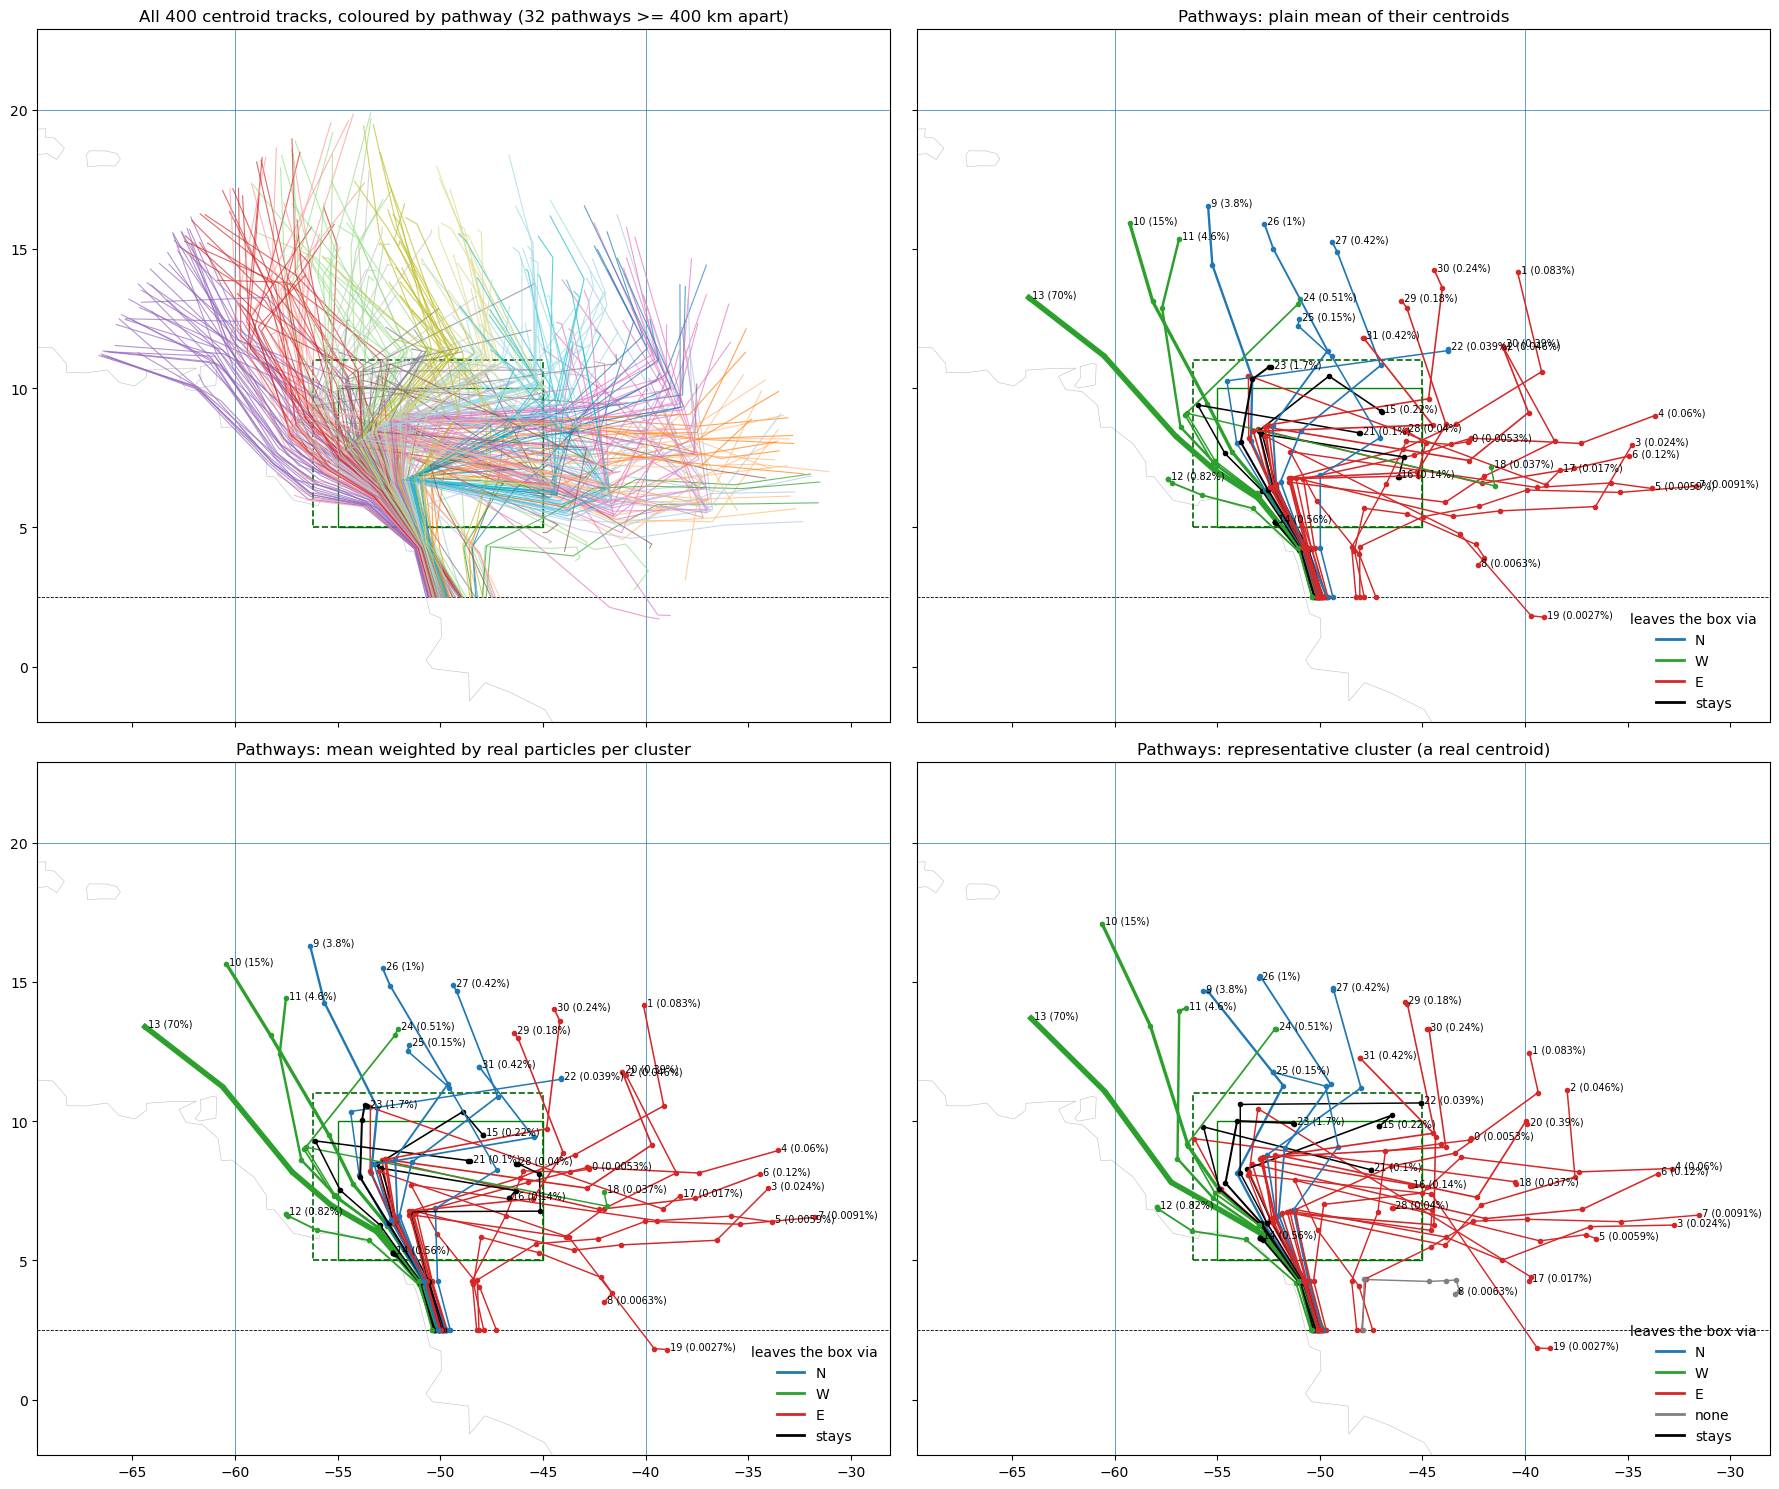

,% of particles,clusters,representative cluster,plain vs weighted [km],plain vs representative [km],weighted vs representative [km]
pathway,,,,,,
13,69.682,41,179,17.0,28.0,31.0
10,14.620,31,99,27.0,76.0,73.0
11,4.596,19,41,33.0,60.0,64.0
9,3.765,25,373,32.0,102.0,95.0
23,1.658,15,231,58.0,90.0,116.0
26,1.026,16,122,15.0,46.0,34.0
12,0.824,3,234,21.0,56.0,37.0
14,0.556,2,40,10.0,84.0,74.0
24,0.509,13,141,42.0,49.0,15.0


In [11]:
def mean_tracks(weights):
    tr, st = [], []
    for i in range(n_path):
        m = PATH_OF == i
        w = weights[m] if weights[m].sum() > 0 else np.ones(m.sum())
        tr.append(np.average(cent_deg[m], axis=0, weights=w))
        st.append(np.average(start_lon[m], weights=w))
    return np.array(tr), np.array(st)

def representative_tracks():
    tr, st, rep = [], [], []
    for i in range(n_path):
        mem = np.where(PATH_OF == i)[0]
        D = track_dist(cent_deg[mem], cent_deg[mem])
        c = mem[D.mean(axis=1).argmin()]        # closest on average to the other members
        tr.append(cent_deg[c]); st.append(start_lon[c]); rep.append(c)
    return np.array(tr), np.array(st), np.array(rep)

tr_plain, st_plain = mean_tracks(np.ones(K))
tr_wmean, st_wmean = mean_tracks(cl_count.astype(float))
tr_rep, st_rep, REP_OF = representative_tracks()

pcmap = plt.get_cmap("tab20", max(n_path, 3))
la_all = np.r_[cent_deg[:, 0::2].ravel(), C.LAT_CROSS]; lo_all = cent_deg[:, 1::2].ravel()
zoom = (lo_all.min() - 3, lo_all.max() + 3, min(la_all.min(), 0) - 2, la_all.max() + 3)

def face_legend(ax, used):
    ax.legend(handles=[plt.Line2D([], [], color=c, lw=2, label=k) for k, c in FACE_COL.items() if k in used],
              title="leaves the box via", frameon=False, loc="lower right")

def draw_pathways(ax, tracks, starts, title):
    # each pathway coloured by the side of the grouping box its drawn track leaves through
    draw_coast(ax); draw_refs(ax)
    fc = faces(tracks, starts)
    for i in range(n_path):
        lo = np.r_[starts[i], tracks[i, 1::2]]; la = np.r_[C.LAT_CROSS, tracks[i, 0::2]]
        ax.plot(lo, la, ".-", color=FACE_COL[fc[i]],
                lw=1 + 3 * np.sqrt(share[i] / share.max()), zorder=3)
        ax.text(lo[-1], la[-1], f" {i} ({share[i]:.2g}%)", fontsize=7, zorder=4)
    face_legend(ax, set(fc))
    ax.set_title(title)

fig, axes = plt.subplots(2, 2, figsize=(18, 15), sharex=True, sharey=True)
ax = axes[0, 0]
draw_coast(ax); draw_refs(ax)
for c in range(K):
    lo, la = centroid_track(c)
    ax.plot(lo, la, "-", color=pcmap(PATH_OF[c]), lw=.8, alpha=.7, zorder=2)
ax.set_title(f"All {K} centroid tracks, coloured by pathway ({n_path} pathways "
             f">= {PATHWAY_SEP_KM} km apart)")
draw_pathways(axes[0, 1], tr_plain, st_plain, "Pathways: plain mean of their centroids")
draw_pathways(axes[1, 0], tr_wmean, st_wmean, "Pathways: mean weighted by real particles per cluster")
draw_pathways(axes[1, 1], tr_rep, st_rep, "Pathways: representative cluster (a real centroid)")
for a in axes.ravel():
    a.set_xlim(zoom[0], zoom[1]); a.set_ylim(zoom[2], zoom[3])
fig.tight_layout(); plt.show()

# how far apart the three versions are, per pathway (mean over radii, km)
diff = pd.DataFrame({
    "% of particles": share.round(3), "clusters": np.bincount(PATH_OF, minlength=n_path),
    "representative cluster": REP_OF,
    "plain vs weighted [km]": np.diag(track_dist(tr_plain, tr_wmean)).round(0),
    "plain vs representative [km]": np.diag(track_dist(tr_plain, tr_rep)).round(0),
    "weighted vs representative [km]": np.diag(track_dist(tr_wmean, tr_rep)).round(0)},
    index=pd.Index(range(n_path), name="pathway"))
diff.sort_values("% of particles", ascending=False)

## Pathways by how they leave the NBC box
Representative cluster of each pathway (the tracks drawn here are also the
ones classified). Green box = NBC box 55-45W / 5-10N.

* **Left:** coloured by the first side the pathway leaves the box through.
* **Right:** pathways that leave the box **two or more times** - they exit,
  come back in, and exit again - coloured by the order of the sides, e.g.
  `N → E` = out through the north side, back in, out through the east side.
  Pathways that leave only once are grey.

The track is followed in small steps along each straight piece between the
points at 2.5N, 200, 500, 1000, 1500 and 2000 km, so a crossing between two
points is not missed.

first exit side: {'E': 17, 'stays': 5, 'W': 5, 'N': 4, 'none': 1}
leave the box 2+ times: 2 pathways, 0.926% of particles; {'W → N': 1, 'E → N': 1}


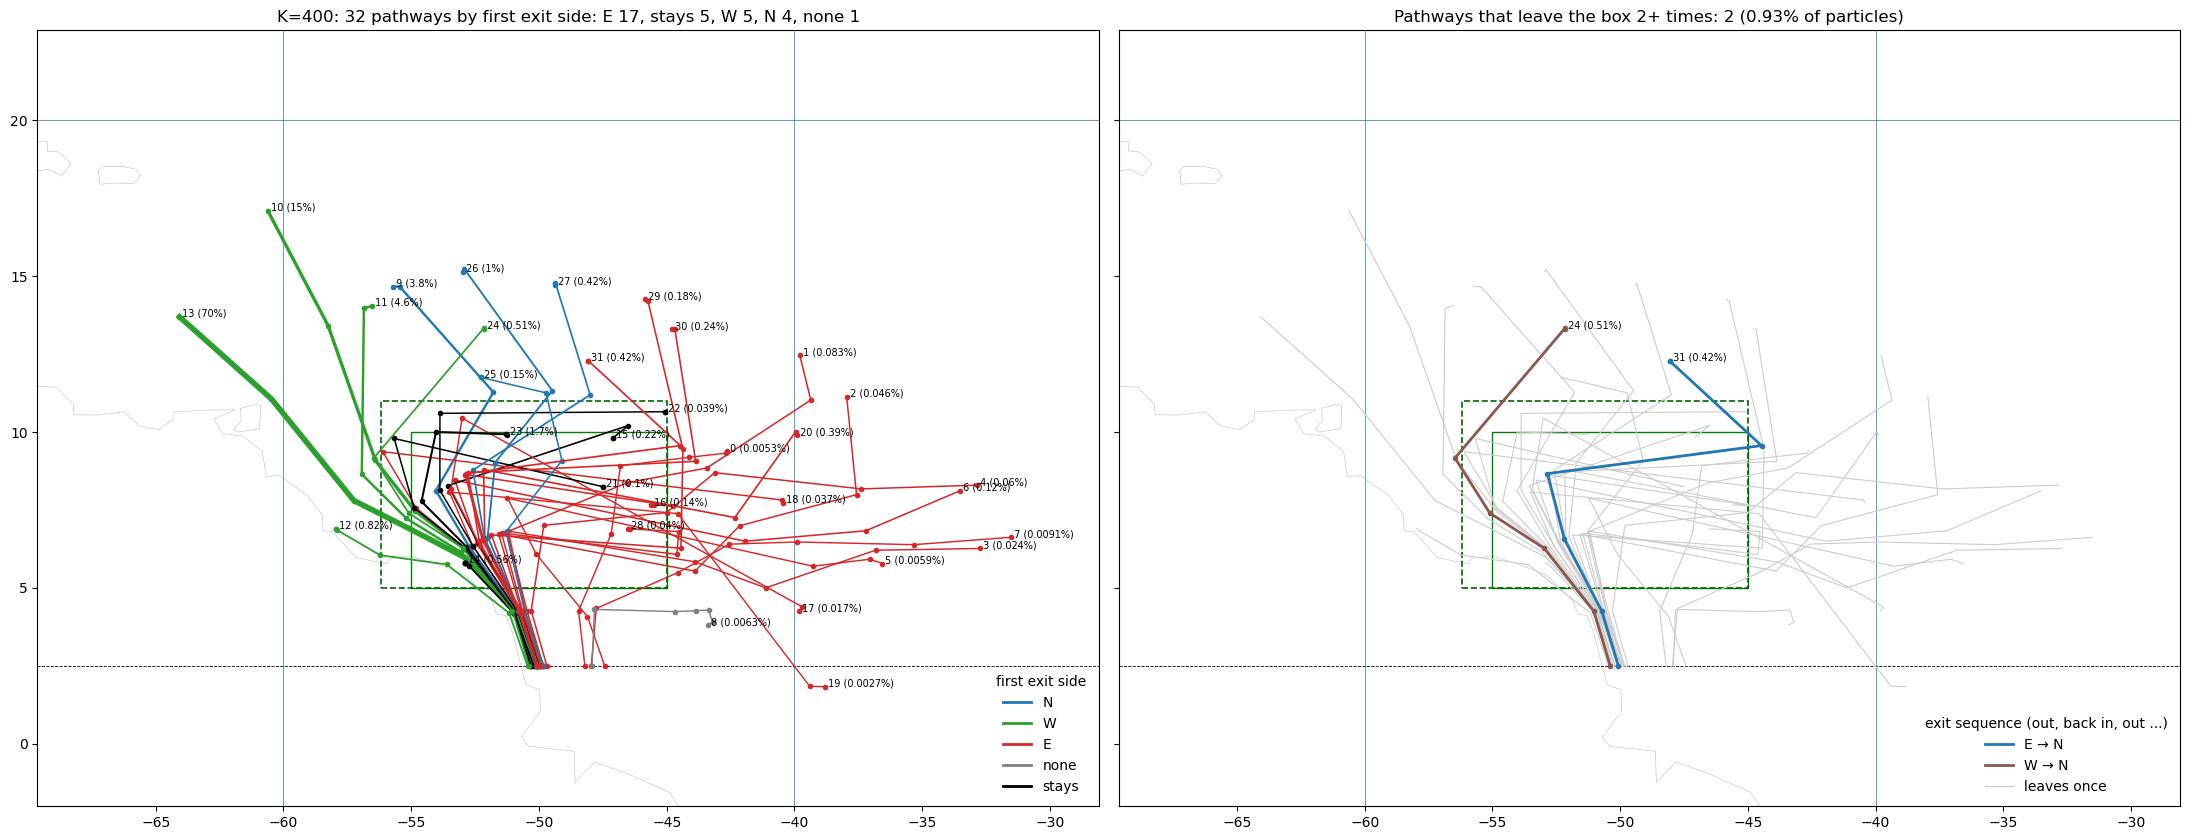

,% of particles,first exit,times it leaves,exit sequence,enters through
pathway,,,,,
24,0.509,W,2,W → N,S → W
31,0.417,E,2,E → N,S → E
13,69.682,W,1,W,S
10,14.620,W,1,W,S
11,4.596,W,1,W,S
9,3.765,N,1,N,S
26,1.026,N,1,N,S
12,0.824,W,1,W,S
27,0.420,N,1,N,S


In [12]:
def box_sequence(lons, lats, n_sub=200):
    # every exit from (and entry into) the NBC box along the track, in order
    lo = np.concatenate([np.linspace(lons[k], lons[k + 1], n_sub, endpoint=False) for k in range(len(lons) - 1)] + [[lons[-1]]])
    la = np.concatenate([np.linspace(lats[k], lats[k + 1], n_sub, endpoint=False) for k in range(len(lats) - 1)] + [[lats[-1]]])
    ins = (lo >= BOX["lon0"]) & (lo <= BOX["lon1"]) & (la >= BOX["lat0"]) & (la <= BOX["lat1"])
    def side(x, y):              # side of the box a point just outside it lies beyond
        d = {"N": y - BOX["lat1"], "S": BOX["lat0"] - y, "W": BOX["lon0"] - x, "E": x - BOX["lon1"]}
        return max(d, key=d.get)
    exits, entries = [], []
    for k in range(len(ins) - 1):
        if ins[k] and not ins[k + 1]:
            exits.append(side(lo[k + 1], la[k + 1]))
        elif not ins[k] and ins[k + 1]:
            entries.append(side(lo[k], la[k]))
    return exits, entries, bool(ins[-1])

def seq_label(exits, ends_inside):
    if not exits:
        return "stays" if ends_inside else "none"
    lab = " → ".join(exits)
    return lab + " (ends inside)" if ends_inside else lab

seq = [box_sequence(np.r_[st_rep[i], tr_rep[i, 1::2]], np.r_[C.LAT_CROSS, tr_rep[i, 0::2]]) for i in range(n_path)]
first_exit = np.array([ex[0] if ex else ("stays" if end else "none") for ex, _, end in seq])
n_exits = np.array([len(ex) for ex, _, _ in seq])
seq_lab = np.array([seq_label(ex, end) for ex, _, end in seq])

bt = pd.DataFrame({"% of particles": share.round(3), "first exit": first_exit, "times it leaves": n_exits,
                   "exit sequence": seq_lab, "enters through": [" → ".join(en) for _, en, _ in seq]},
                  index=pd.Index(range(n_path), name="pathway"))
print("first exit side:", pd.Series(first_exit).value_counts().to_dict())
print("leave the box 2+ times:", int((n_exits >= 2).sum()), "pathways,",
      f"{share[n_exits >= 2].sum():.3f}% of particles;",
      pd.Series(seq_lab[n_exits >= 2]).value_counts().to_dict())

multi = sorted(set(seq_lab[n_exits >= 2]))
mcmap = plt.get_cmap("tab10", max(len(multi), 3))
SEQ_COL = {L: mcmap(i) for i, L in enumerate(multi)}

fig, axes = plt.subplots(1, 2, figsize=(22, 8.5), sharex=True, sharey=True)
for ax in axes:
    draw_coast(ax); draw_refs(ax)
    ax.set_xlim(zoom[0], zoom[1]); ax.set_ylim(zoom[2], zoom[3])
for i in range(n_path):
    lo = np.r_[st_rep[i], tr_rep[i, 1::2]]; la = np.r_[C.LAT_CROSS, tr_rep[i, 0::2]]
    lw = 1 + 3 * np.sqrt(share[i] / share.max())
    axes[0].plot(lo, la, ".-", color=FACE_COL[first_exit[i]], lw=lw, zorder=3)
    axes[0].text(lo[-1], la[-1], f" {i} ({share[i]:.2g}%)", fontsize=7, zorder=4)
    if n_exits[i] >= 2:
        axes[1].plot(lo, la, ".-", color=SEQ_COL[seq_lab[i]], lw=max(lw, 2), zorder=4)
        axes[1].text(lo[-1], la[-1], f" {i} ({share[i]:.2g}%)", fontsize=7, zorder=5)
    else:
        axes[1].plot(lo, la, "-", color="0.8", lw=.8, zorder=2)
axes[0].legend(handles=[plt.Line2D([], [], color=c, lw=2, label=k) for k, c in FACE_COL.items()
                        if k in set(first_exit)], title="first exit side", frameon=False, loc="lower right")
axes[0].set_title(f"K={K}: {n_path} pathways by first exit side: " + ", ".join(
    f"{k} {v}" for k, v in pd.Series(first_exit).value_counts().items()))
axes[1].legend(handles=[plt.Line2D([], [], color=c, lw=2, label=k) for k, c in SEQ_COL.items()]
               + [plt.Line2D([], [], color="0.8", lw=1, label="leaves once")],
               title="exit sequence (out, back in, out ...)", frameon=False, loc="lower right")
axes[1].set_title(f"Pathways that leave the box 2+ times: {int((n_exits >= 2).sum())} "
                  f"({share[n_exits >= 2].sum():.2g}% of particles)")
fig.tight_layout(); plt.show()
bt.sort_values(["times it leaves", "% of particles"], ascending=False)

## Hierarchical view: how the clusters group into pathways
The pathways above are made by **complete-linkage** clustering of the centroid
tracks (distance = mean distance between their points at 200 ... 2000 km),
cut at `PATHWAY_SEP_KM`. The dendrograms show that tree:

* **left:** all K centroids (only the top of the tree, the last merges, is
  drawn); dashed line = the cut, every branch below it is one pathway;
* **right:** the pathways themselves (representative tracks), labelled with
  pathway number, first exit side of the grouping box and share of particles -
  pathways that join low in this tree are the closest candidates to merge by
  hand.

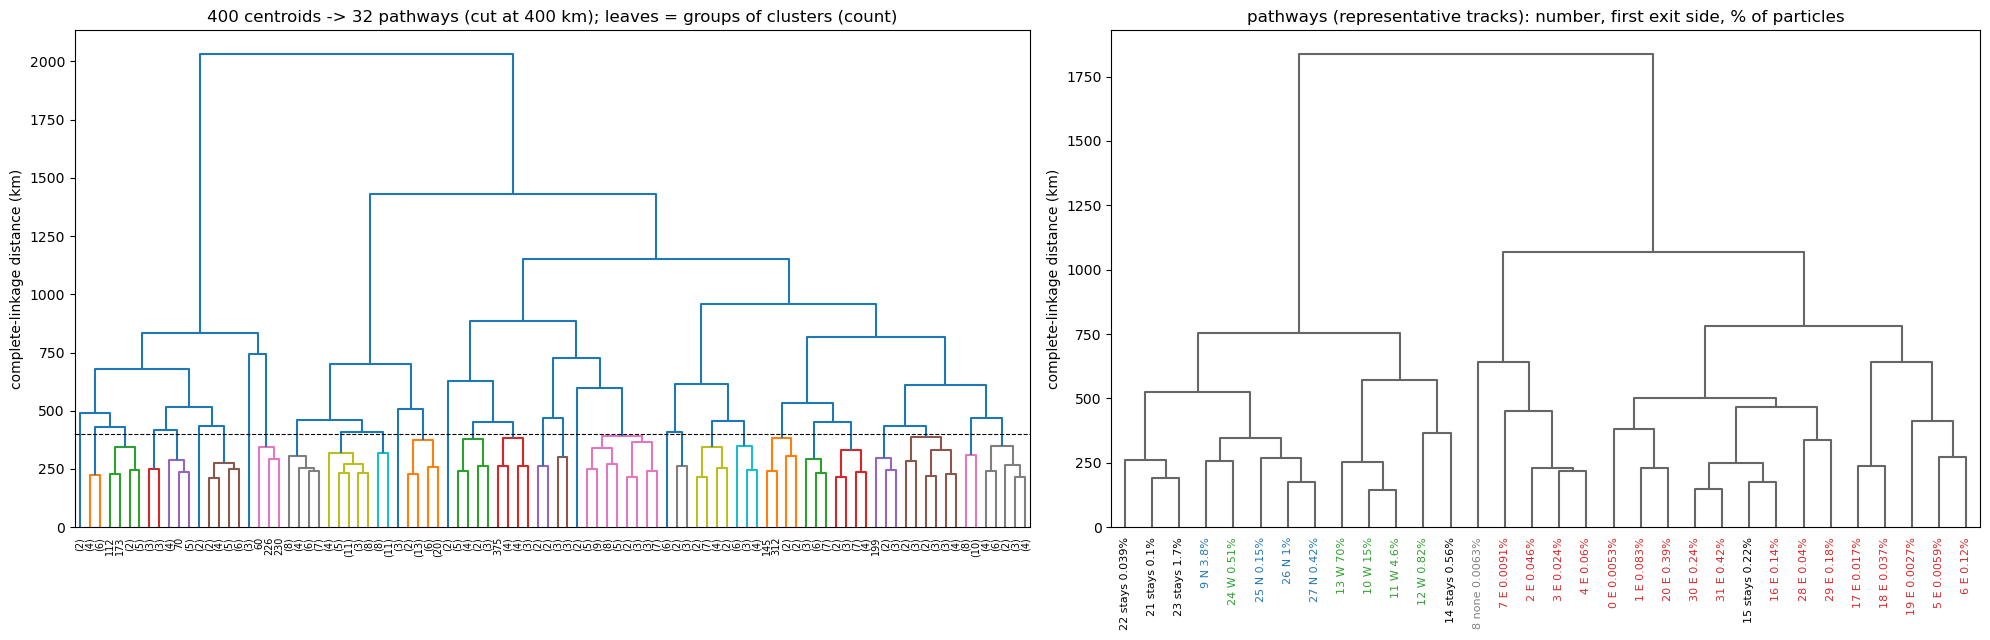

In [13]:
from scipy.cluster.hierarchy import dendrogram
Z_cl = linkage(squareform(track_dist(cent_deg, cent_deg), checks=False), "complete")
Z_pw = linkage(squareform(track_dist(tr_rep, tr_rep), checks=False), "complete")
fig, ax = plt.subplots(1, 2, figsize=(20, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
dendrogram(Z_cl, ax=ax[0], truncate_mode="lastp", p=min(3 * n_path, K), color_threshold=PATHWAY_SEP_KM,
           show_leaf_counts=True, leaf_rotation=90, leaf_font_size=7)
ax[0].axhline(PATHWAY_SEP_KM, color="k", ls="--", lw=.8)
ax[0].set_ylabel("complete-linkage distance (km)")
ax[0].set_title(f"{K} centroids -> {n_path} pathways (cut at {PATHWAY_SEP_KM} km); leaves = groups of clusters (count)")
labels = [f"{i} {first_exit[i]} {share[i]:.2g}%" for i in range(n_path)]
dn = dendrogram(Z_pw, ax=ax[1], labels=labels, leaf_rotation=90, leaf_font_size=8,
                color_threshold=0, above_threshold_color="0.4")
for t in ax[1].get_xticklabels():
    t.set_color(FACE_COL[t.get_text().split()[1]])
ax[1].set_ylabel("complete-linkage distance (km)")
ax[1].set_title("pathways (representative tracks): number, first exit side, % of particles")
fig.tight_layout(); plt.show()

## Hierarchical grouping of the clusters, on the map
The K centroid tracks are grouped by **complete-linkage** hierarchical
clustering (distance = mean distance between their points at 200 ... 2000 km,
the same distance as for the pathways) and the tree is cut into `N_GROUPS`
groups. Thin lines = centroid tracks coloured by group; thick line = the
group's mean track weighted by its real particles, labelled with group number
and share of all particles. Each panel is one cut, so going from left to
right shows which clusters split off first.

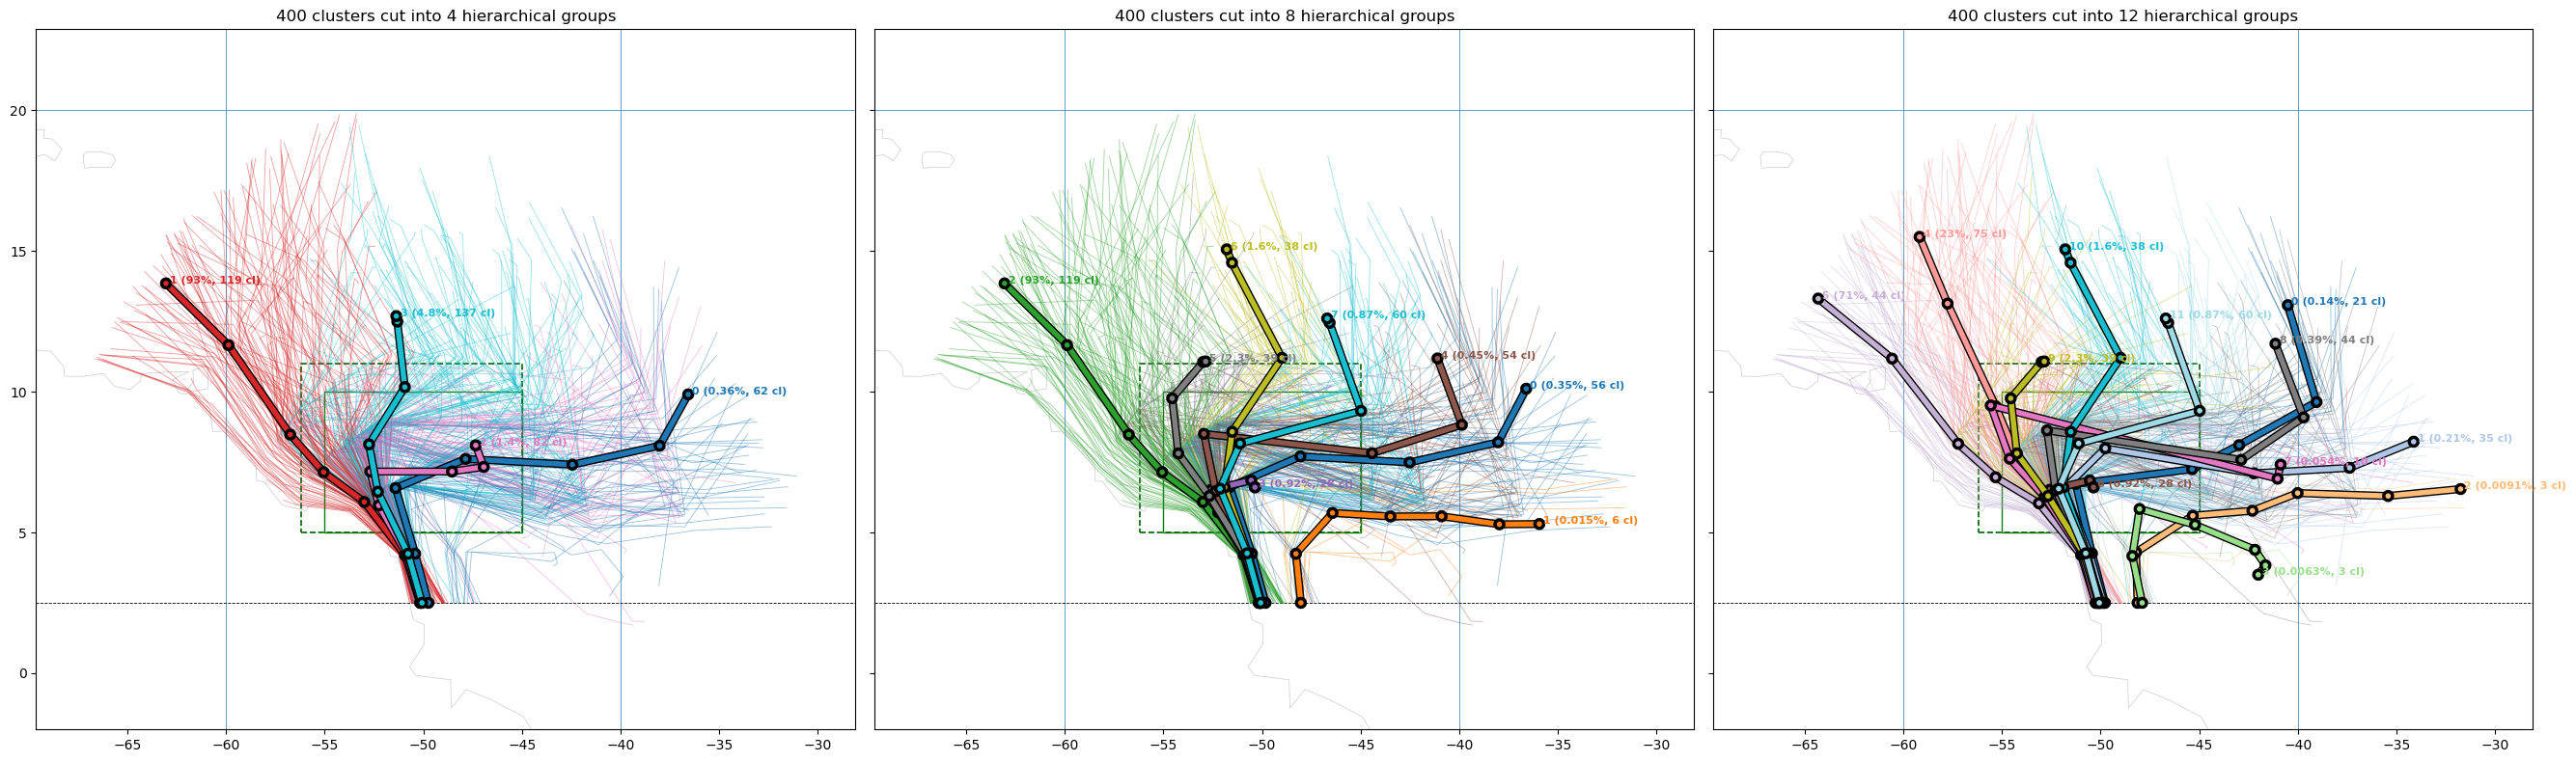

,group (4 groups),group (8 groups),group (12 groups),% of particles,first exit
pathway,,,,,
13,[1],[2],[5],69.682,W
10,[1],[2],[4],14.620,W
11,[1],[2],[4],4.596,W
9,[1],[2],[4],3.765,N
23,[3],[5],[9],1.658,stays
26,[3],[6],[10],1.026,N
12,[1],[2],[5],0.824,W
14,[2],[3],[6],0.556,stays
24,[3],[5],[9],0.509,W


In [14]:
N_GROUPS = [4, 8, 12]           # cuts of the tree to show (one panel each)
import matplotlib.patheffects as pe
# Z_cl = the centroid tree of the left dendrogram above
fig, axes = plt.subplots(1, len(N_GROUPS), figsize=(9 * len(N_GROUPS), 8), sharex=True, sharey=True,
                         squeeze=False)
HGROUP = {}
for ax, ng in zip(axes[0], N_GROUPS):
    hg = fcluster(Z_cl, t=ng, criterion="maxclust") - 1
    HGROUP[ng] = hg
    gcmap = plt.get_cmap("tab10" if hg.max() < 10 else "tab20", max(hg.max() + 1, 3))
    draw_coast(ax); draw_refs(ax)
    for c in range(K):
        lo, la = centroid_track(c)
        ax.plot(lo, la, "-", color=gcmap(hg[c]), lw=.6, alpha=.45, zorder=2)
    for gi in range(hg.max() + 1):
        mem = hg == gi
        wts = cl_count[mem] if cl_count[mem].sum() > 0 else np.ones(mem.sum())
        tr = np.average(cent_deg[mem], axis=0, weights=wts)
        st = np.average(start_lon[mem], weights=wts)
        lo = np.r_[st, tr[1::2]]; la = np.r_[C.LAT_CROSS, tr[0::2]]
        g_share = 100 * cl_count[mem].sum() / cl_count.sum()
        ax.plot(lo, la, ".-", color=gcmap(gi), lw=4, zorder=4,
                path_effects=[pe.withStroke(linewidth=6, foreground="k")])
        ax.text(lo[-1], la[-1], f" {gi} ({g_share:.2g}%, {mem.sum()} cl)", fontsize=8, zorder=5,
                fontweight="bold", color=gcmap(gi))
    ax.set_xlim(zoom[0], zoom[1]); ax.set_ylim(zoom[2], zoom[3])
    ax.set_title(f"{K} clusters cut into {hg.max() + 1} hierarchical groups")
fig.tight_layout(); plt.show()

# which pathways (>= PATHWAY_SEP_KM apart) end up in which group, per cut
pd.DataFrame({f"group ({ng} groups)": [sorted(set(HGROUP[ng][PATH_OF == i])) for i in range(n_path)]
              for ng in N_GROUPS} | {"% of particles": share.round(3), "first exit": first_exit},
             index=pd.Index(range(n_path), name="pathway")).sort_values("% of particles", ascending=False)

## Hierarchical groups versus real trajectories
For the 8- and 12-group cuts above: one panel per group with real particle
tracks after the 2.5N crossing.

* **blue** = particles of the **fit sample** (the balanced 500,000 k-means was
  trained on) that fall in the group;
* **green** = particles **not** in the fit sample - k-means never saw them,
  they are only assigned to their nearest centroid. If a group is real, the
  green tracks follow the blue ones;
* **orange** = the group's mean track (weighted by real particles).

Title: group number, its share of all particles, and how many fit / non-fit
particles it has.

read 793 real tracks; 14,568,653 non-fit particles labelled


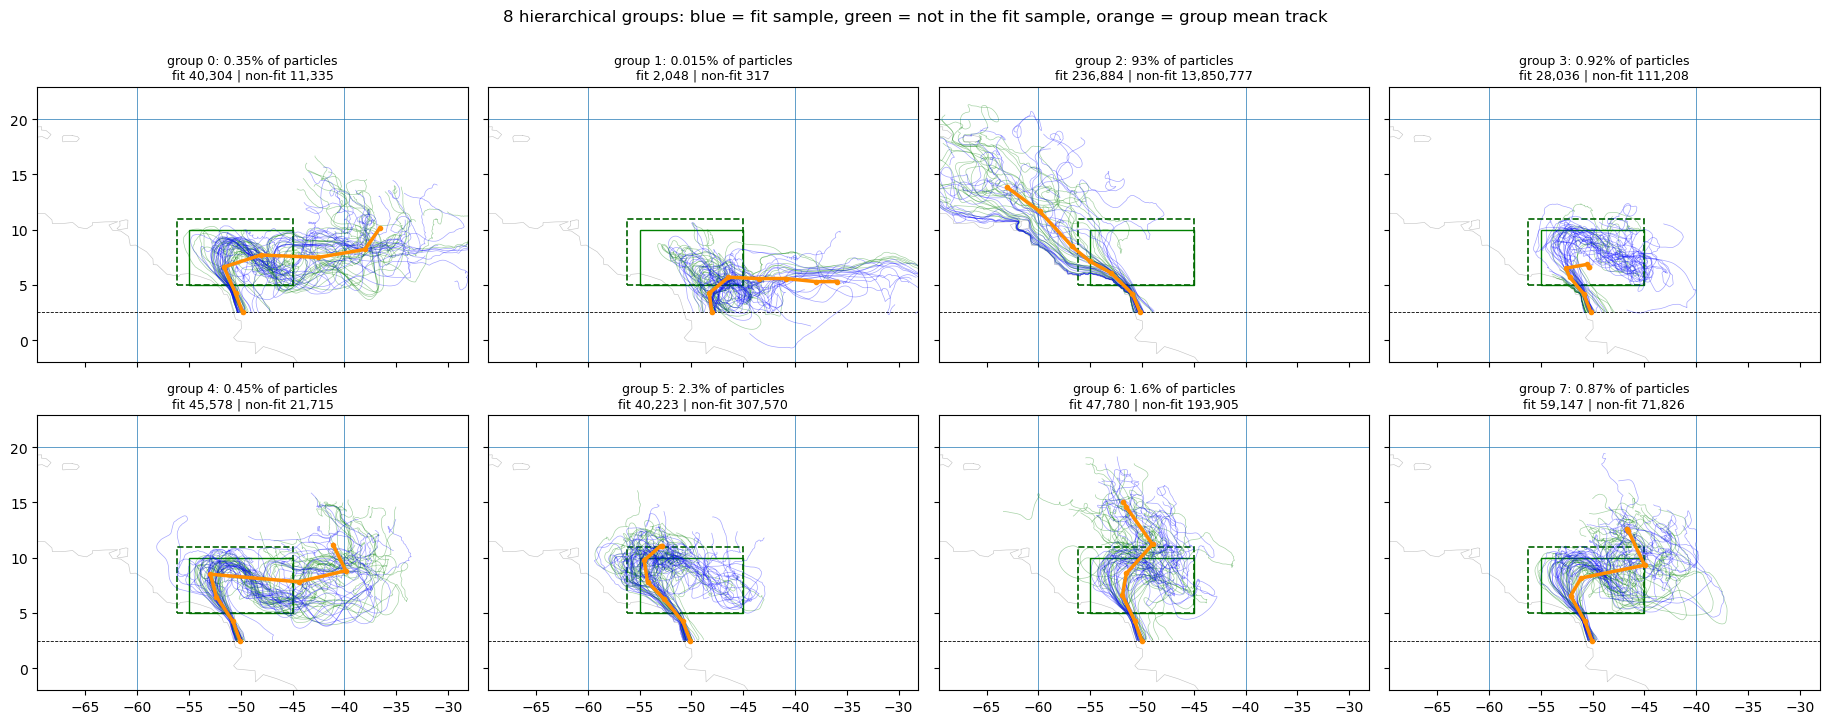

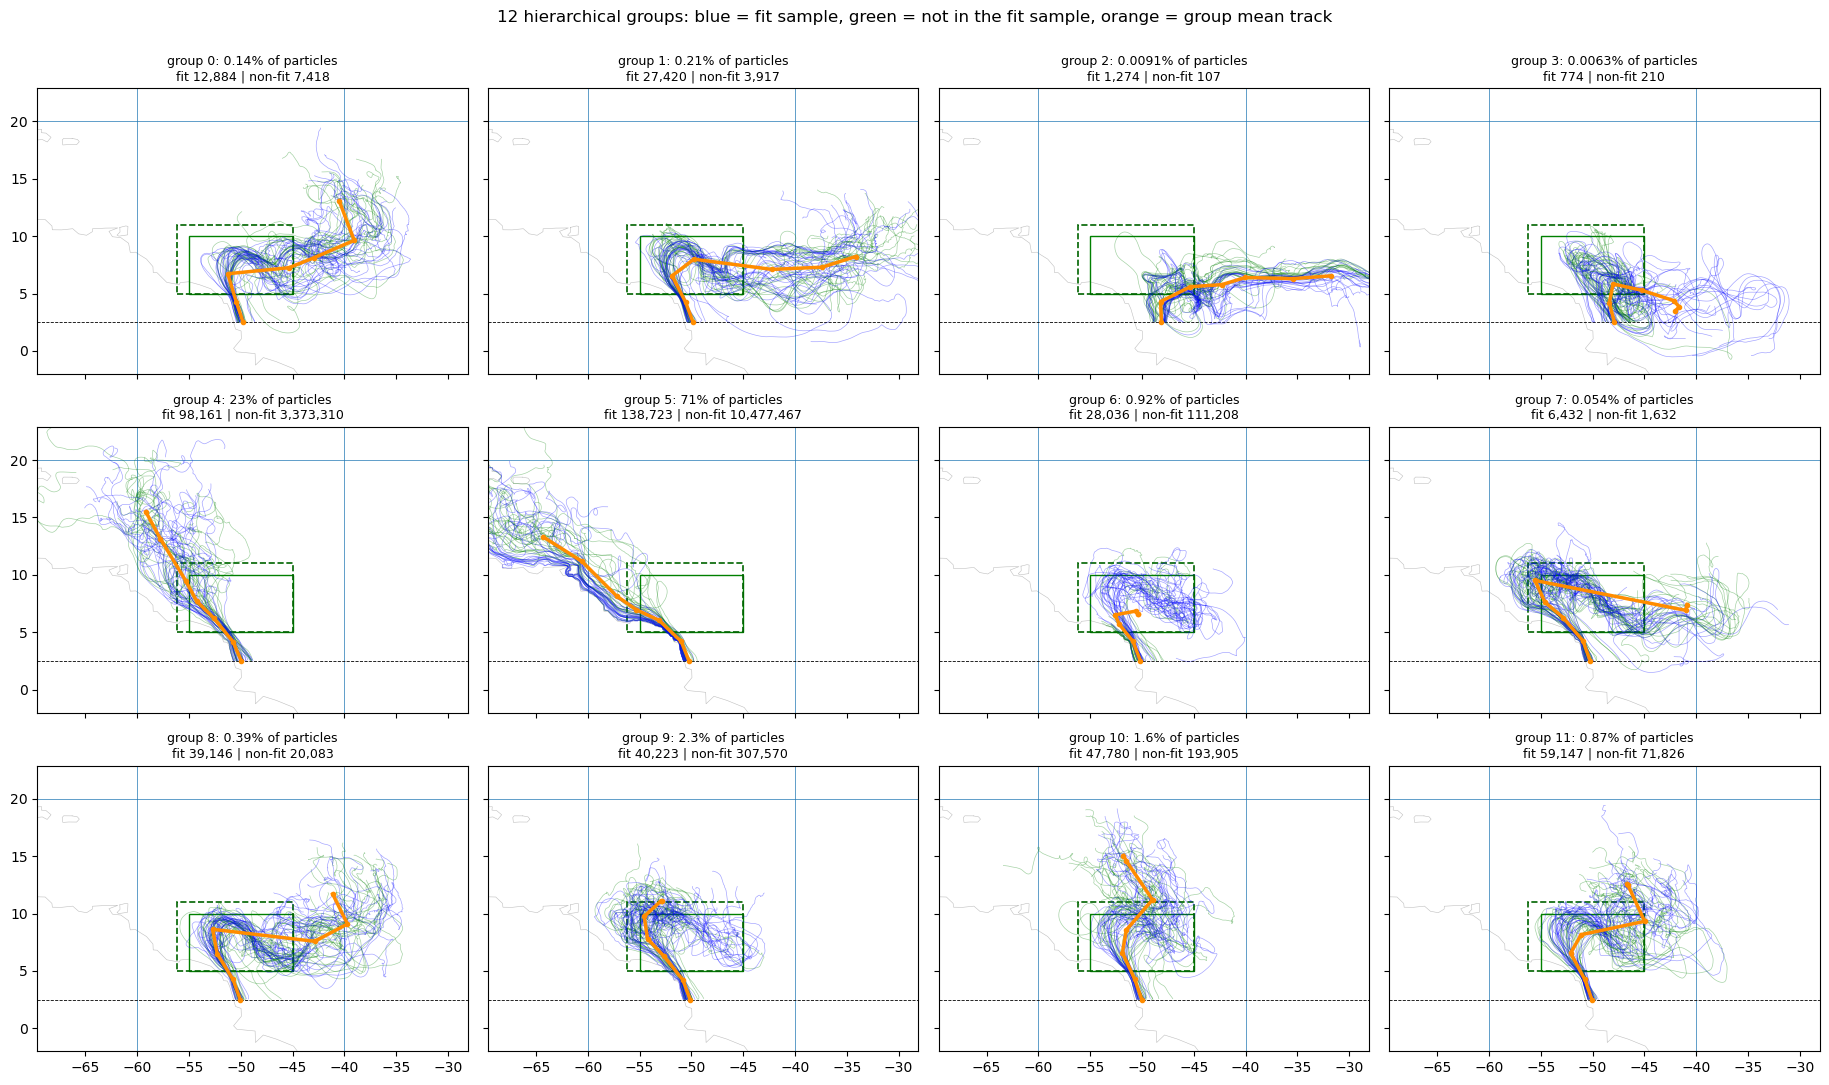

In [15]:
REAL_CUTS = [8, 12]              # which cuts of the tree to show (any number of groups)
MEMBERS_PER_GROUP = 25           # tracks of each kind (blue / green) per panel
N_IO_THREADS = int(os.environ.get("SLURM_CPUS_PER_TASK", 16))
for ng in REAL_CUTS:             # cuts not drawn on the map above are cut from the same tree here
    if ng not in HGROUP:
        HGROUP[ng] = fcluster(Z_cl, t=ng, criterion="maxclust") - 1

trained = np.zeros(len(fitset), dtype=bool); trained[idx] = True
nf = np.where(~trained)[0]                                   # rows of fitset not in the fit sample
lab_fit = km.labels_                                         # cluster of each fit-sample particle (order of idx)
lab_nf = km.predict(scaler.transform(X_all[nf]) * W)         # cluster of each non-fit particle
cols = ["trajectory_id", "store", "row", "traj", "cross_obs"]
picks = []
for ng in REAL_CUTS:
    hg = HGROUP[ng]
    for kind, rows_, labs in (("fit", idx, lab_fit), ("nonfit", nf, lab_nf)):
        d = fitset.iloc[rows_][cols].assign(group=hg[labs], kind=kind, cut=ng)
        picks.append(pd.concat([g.sample(min(MEMBERS_PER_GROUP, len(g)), random_state=C.RANDOM_STATE)
                                for _, g in d.groupby("group")]))
pick_all = pd.concat(picks, ignore_index=True)
gpaths = P.read_paths(pick_all.drop_duplicates("trajectory_id"), n_jobs=N_IO_THREADS)
print(f"read {len(gpaths):,} real tracks; {len(nf):,} non-fit particles labelled")

for ng in REAL_CUTS:
    hg = HGROUP[ng]
    n_fit = np.bincount(hg[lab_fit], minlength=hg.max() + 1)
    n_nf = np.bincount(hg[lab_nf], minlength=hg.max() + 1)
    ncol = 4; nrow = int(np.ceil((hg.max() + 1) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.6 * nrow), squeeze=False, sharex=True, sharey=True)
    for gi in range(hg.max() + 1):
        ax = axes[gi // ncol][gi % ncol]
        draw_coast(ax); draw_refs(ax)
        sel = pick_all[(pick_all.cut == ng) & (pick_all.group == gi)]
        for kind, col in (("nonfit", "green"), ("fit", "blue")):
            for tid, k0 in sel.loc[sel.kind == kind, ["trajectory_id", "cross_obs"]].itertuples(index=False):
                lo, la = gpaths[int(tid)]
                m = ~(np.isnan(lo[k0:]) | np.isnan(la[k0:]))
                ax.plot(lo[k0:][m], la[k0:][m], "-", color=col, lw=.5, alpha=.35, zorder=2)
        mem = hg == gi
        wts = cl_count[mem] if cl_count[mem].sum() > 0 else np.ones(mem.sum())
        tr = np.average(cent_deg[mem], axis=0, weights=wts); st = np.average(start_lon[mem], weights=wts)
        ax.plot(np.r_[st, tr[1::2]], np.r_[C.LAT_CROSS, tr[0::2]], ".-", color="darkorange", lw=2.5, zorder=4)
        ax.set_xlim(zoom[0], zoom[1]); ax.set_ylim(zoom[2], zoom[3])
        g_share = 100 * cl_count[mem].sum() / cl_count.sum()
        ax.set_title(f"group {gi}: {g_share:.2g}% of particles\nfit {n_fit[gi]:,} | non-fit {n_nf[gi]:,}", fontsize=9)
    for j in range(hg.max() + 1, nrow * ncol):
        axes[j // ncol][j % ncol].axis("off")
    fig.suptitle(f"{ng} hierarchical groups: blue = fit sample, green = not in the fit sample, "
                 f"orange = group mean track", y=1.0)
    fig.tight_layout(); plt.show()